# Export data

In [6]:
import scanpy as sc
from scatlastb_utils.io import read_anndata

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
file_path = 'data/pipeline/batch_analysis/collect/dataset~batch_integration_pseudobulk.zarr'

In [26]:
adata = read_anndata(file_path)

dask: False, backed: False
Read slot "X", store as "X"...
shape: (3564, 27957)
Read slot "layers", store as "layers"...
Read slot "obs", store as "obs"...
shape: (3564, 110)
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 12/12 [00:00<00:00, 200.06it/s]

Read slot "obsp", store as "obsp"...



Read obsp slots as_dask=False: 100%|██████████| 2/2 [00:00<00:00, 97.21it/s]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 5/5 [00:00<00:00, 55.38it/s]

Read slot "var", store as "var"...


shape: (27957, 12)
Read slot "varm", store as "varm"...
Read slot "varp", store as "varp"...
shape: (3564, 27957)


In [27]:
adata.obsm

AxisArrays with keys: X_emb--harmony_dataset, X_emb--harmony_sample, X_emb--scanvi_dataset, X_emb--scanvi_sample, X_emb--scvi_dataset, X_emb--scvi_sample, X_umap--harmony_dataset, X_umap--harmony_sample, X_umap--scanvi_dataset, X_umap--scanvi_sample, X_umap--scvi_dataset, X_umap--scvi_sample

In [28]:
adata

AnnData object with n_obs × n_vars = 3564 × 27957
    obs: 'group', 'is_primary_data', 'user_qc_status', 'alternative_qc_status', 'majority_consensus_low_agreement', 'BMI', 'age_or_mean_of_age_range', 'anatomical_region_ccf_score', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'leiden_1', 'leiden_2', 'log10_total_counts', 'n_genes_detected', 'original_ann_highest_res', 'size_factors', 'scrublet_score', 'n_counts', 'n_genes', 'percent_mito', 'n_counts_mito', 'percent_ribo', 'n_counts_ribo', 'percent_hb', 'n_counts_hb', 'majority_consensus_agreement', 'suspension_type', 'donor_id', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'age_range', 'ann_coarse_for_GWAS_and_modeling',

In [53]:
colors = [
    'majority_consensus',
    'majority_consensus_agreement',
    'sex',
    'BMI',
    'age_or_mean_of_age_range',
    'tissue_level_2',
]

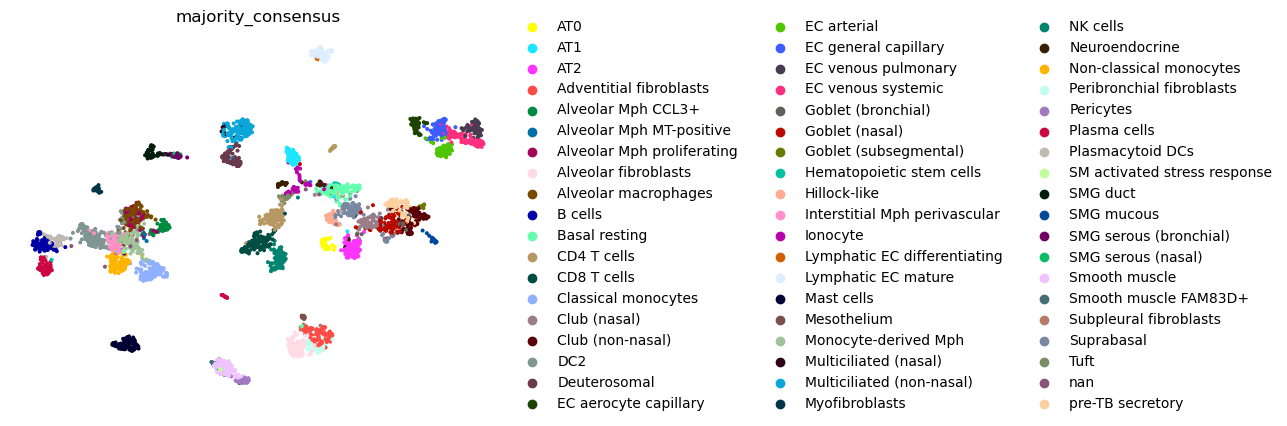

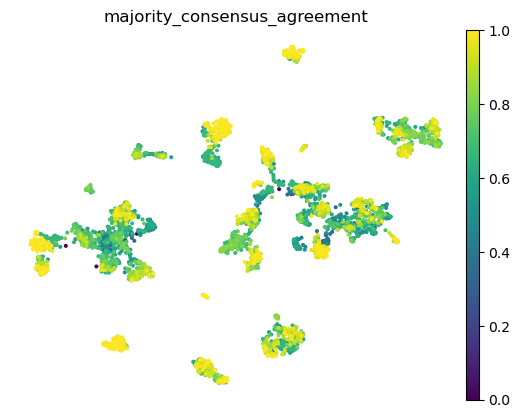

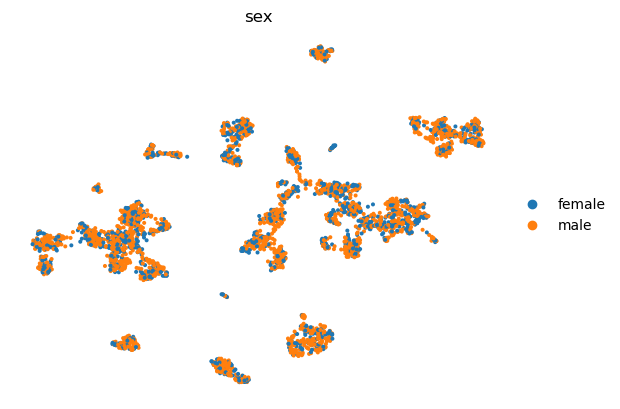

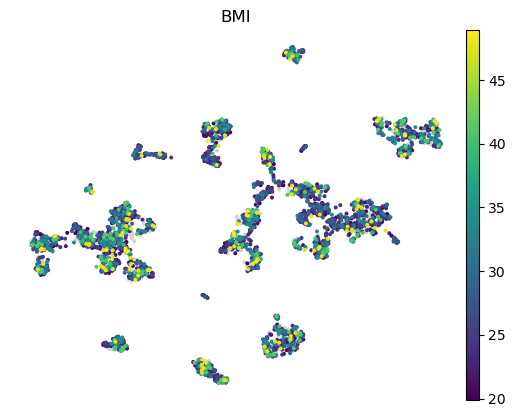

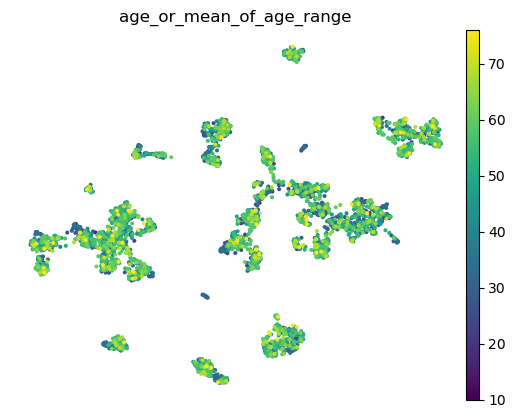

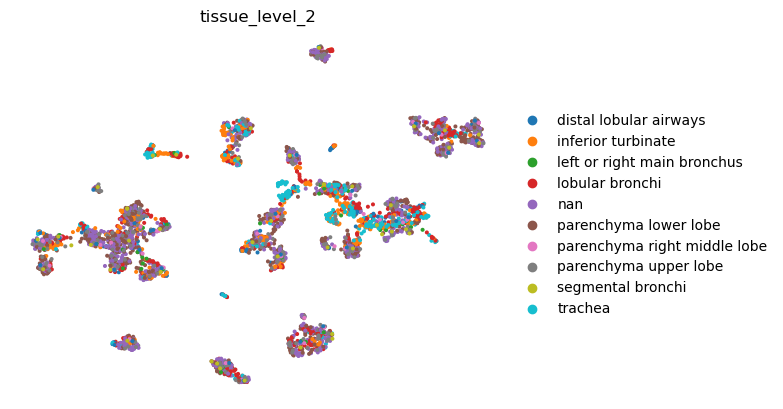

In [54]:
for color in colors:
    sc.pl.embedding(
        adata,
        basis='X_umap--harmony_dataset',
        frameon=False,
        color=color,
    )

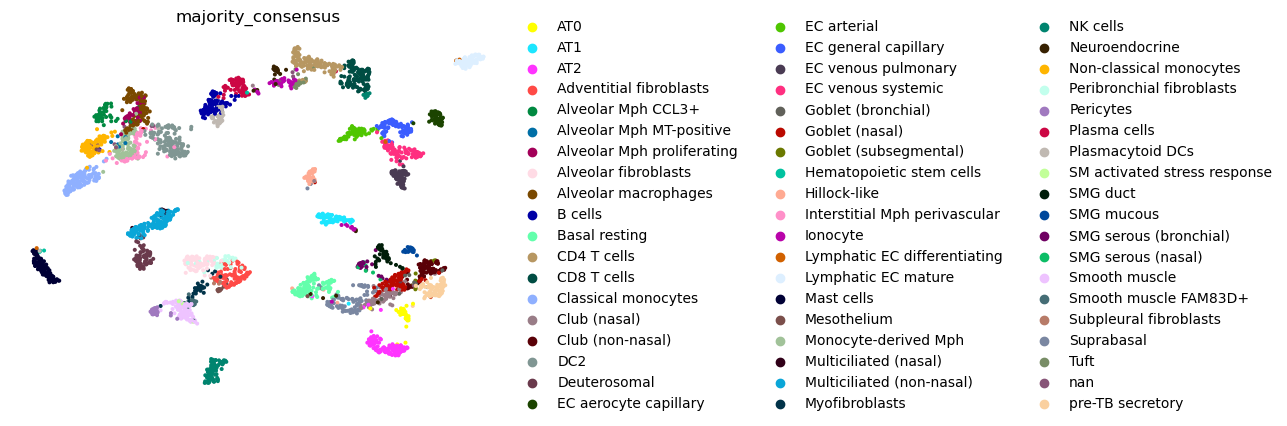

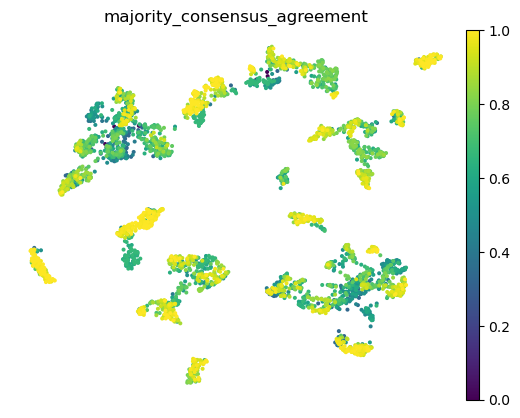

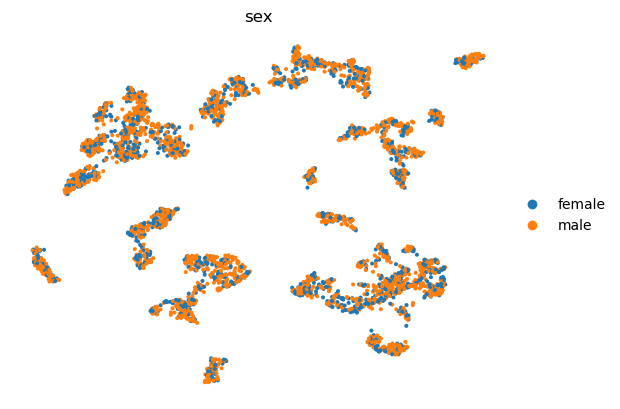

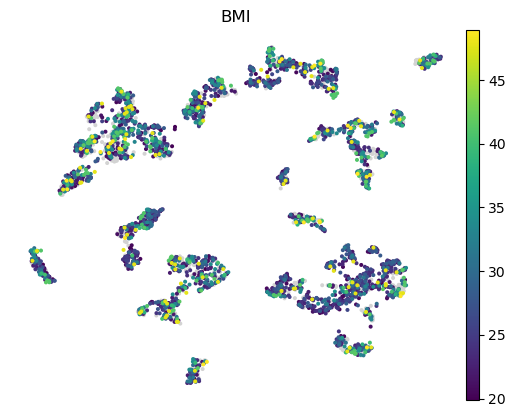

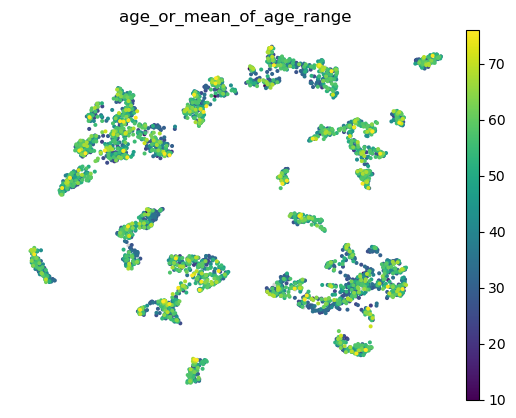

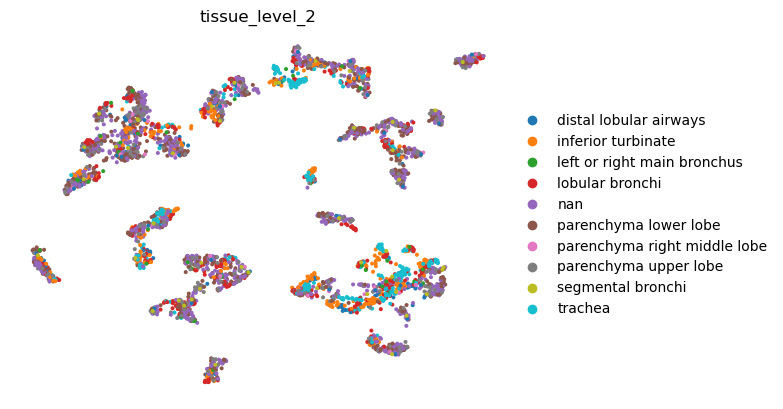

In [55]:
for color in colors:
    sc.pl.embedding(
        adata,
        basis='X_umap--harmony_sample',
        frameon=False,
        color=color,
    )

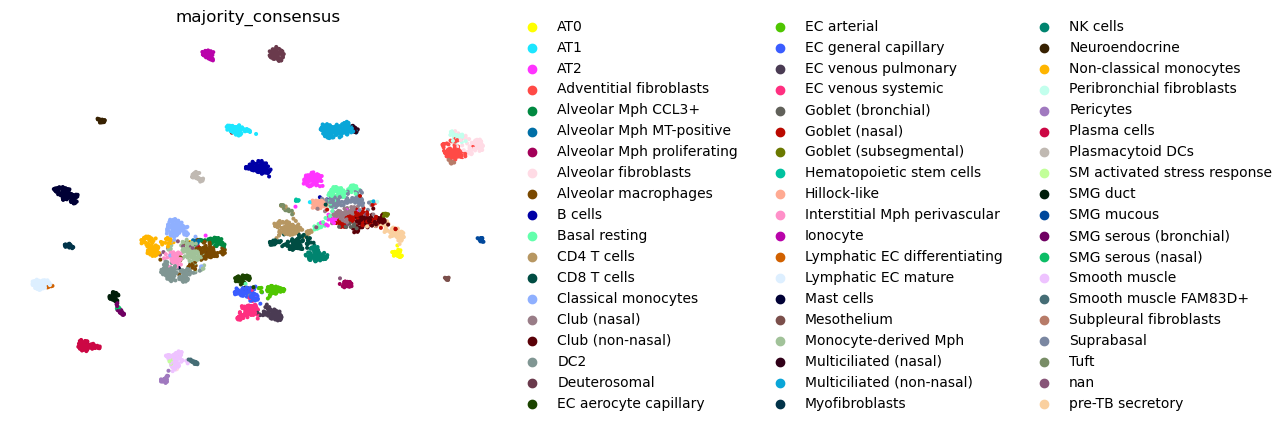

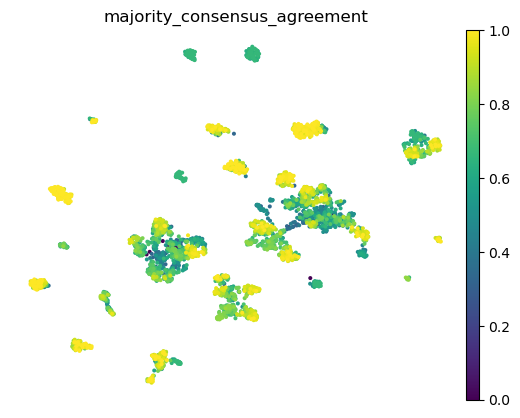

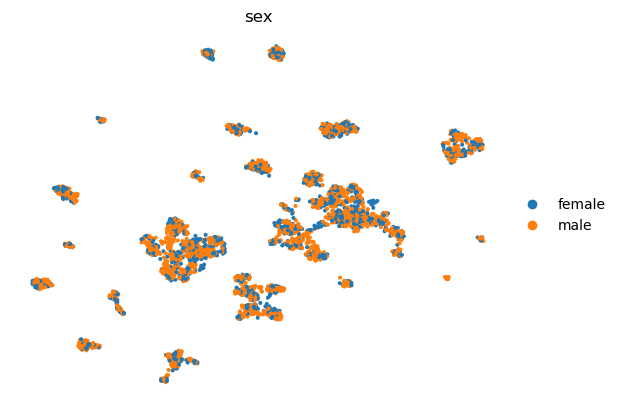

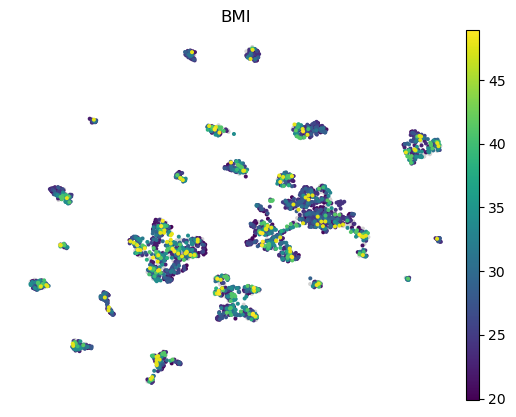

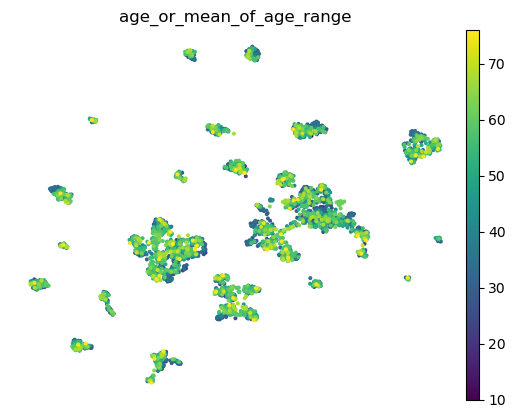

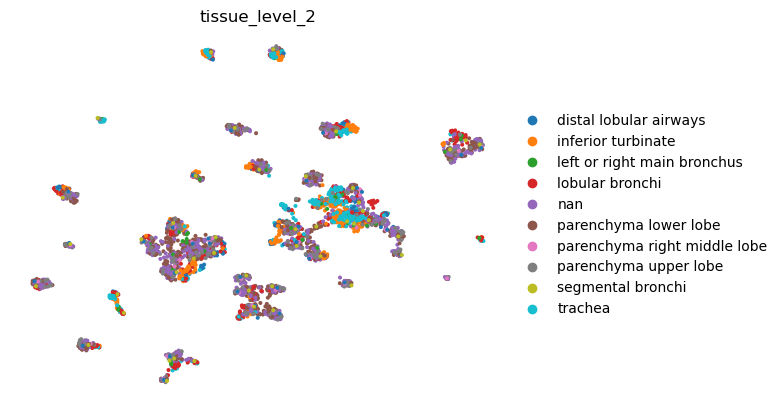

In [56]:
for color in colors:
    sc.pl.embedding(
        adata,
        basis='X_umap--scvi_dataset',
        frameon=False,
        color=color,
    )

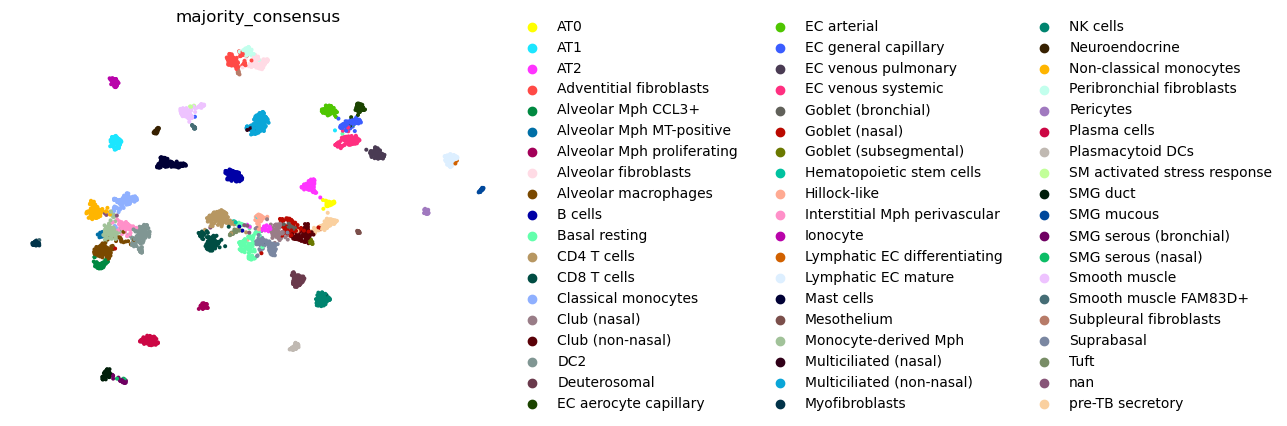

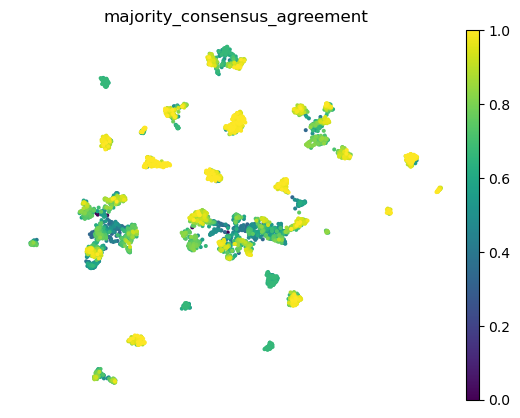

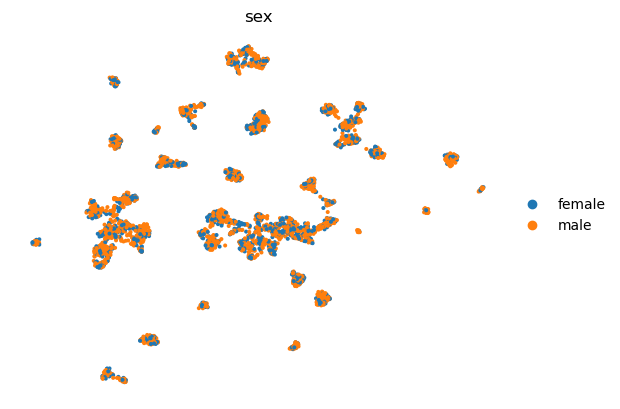

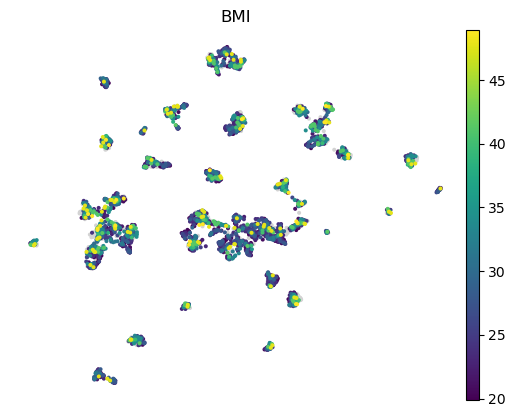

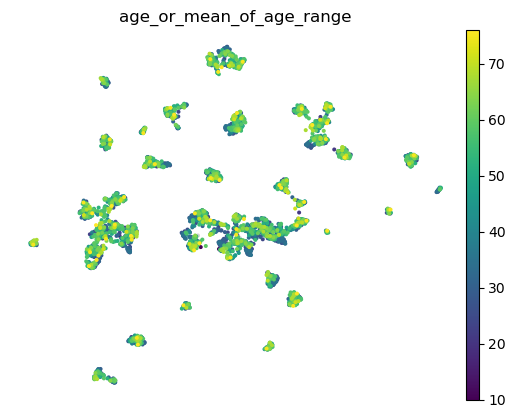

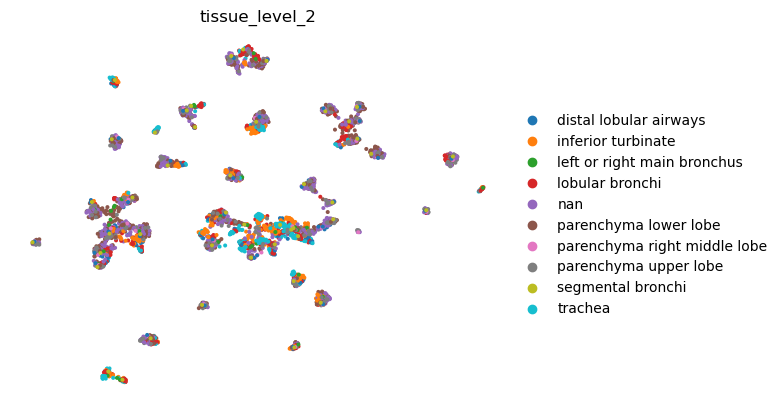

In [57]:
for color in colors:
    sc.pl.embedding(
        adata,
        basis='X_umap--scvi_sample',
        frameon=False,
        color=color,
    )

In [36]:
adata.write_h5ad('data/output/export/hlca_batch_pseudobulk.h5ad', compression='lzf')